In [ ]:
import numpy as np

# 1. Corpus
corpus = [
    "cats like milk",
    "cats drink milk",
    "dogs like milk",
    "dogs chase balls",
    "cats chase balls"
]

# 2. Build vocabulary
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)
print("Vocabulary:", vocab)

# Hyperparameters
window = 1
d = 3
learning_rate = 0.05
epochs = 500

# 3. Generate center-context training pairs
pairs = []

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):
        for j in range(max(0, i - window),
                       min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Training pairs:", (pairs))

Vocabulary: ['balls', 'cats', 'chase', 'dogs', 'drink', 'like', 'milk']
Training pairs: [(1, 5), (5, 1), (5, 6), (6, 5), (1, 4), (4, 1), (4, 6), (6, 4), (3, 5), (5, 3), (5, 6), (6, 5), (3, 2), (2, 3), (2, 0), (0, 2), (1, 2), (2, 1), (2, 0), (0, 2)]



Learned word embeddings:
balls [-1.266 -1.971 -1.919]
cats [ 0.009 -1.334  0.439]
chase [ 1.113  0.284 -1.355]
dogs [-1.852 -1.044  0.163]
drink [0.983 1.665 1.2  ]
like [-0.486  1.588 -0.12 ]
milk [-0.314 -0.637  2.018]


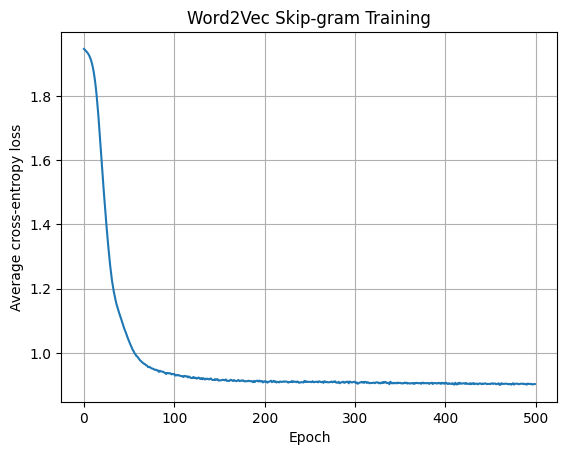

In [ ]:

# 4. Initialize parameters randomly
np.random.seed(42)

E = np.random.randn(V, d) * 0.1
W = np.random.randn(d, V) * 0.1

# 5. Softmax function
def softmax(x):
    x = x - np.max(x)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x)

# 6. Train Skip-gram
losses = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0

    for center, context in pairs:

        # Forward pass
        h = E[center].copy()
        scores = h @ W
        probabilities = softmax(scores)

        # Cross-entropy loss
        loss = -np.log(probabilities[context] + 1e-12)
        total_loss += loss

        # Backpropagation
        error = probabilities.copy()
        error[context] -= 1

        gradient_W = np.outer(h, error)
        gradient_h = W @ error

        # Update parameters
        W -= learning_rate * gradient_W
        E[center] -= learning_rate * gradient_h

    losses.append(total_loss / len(pairs))

# 7. Print learned embeddings
print("\nLearned word embeddings:")
for word, idx in word_to_id.items():
    print(word, np.round(E[idx], 3))

# 8. Plot training loss
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy loss")
plt.title("Word2Vec Skip-gram Training")
plt.grid(True)
plt.show()

In [ ]:
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b) + 1e-12
    )

def similar_words(word, top_k=3):
    idx = word_to_id[word]
    scores = []

    for j in range(V):
        if j != idx:
            sim = cosine_similarity(E[idx], E[j])
            scores.append((id_to_word[j], sim))

    return sorted(scores, key=lambda x: x[1], reverse=True)[:top_k]

print("Words similar to cats:", similar_words("cats"))
print("Words similar to dogs:", similar_words("dogs"))

Words similar to cats: [('milk', np.float64(0.5770610126869122)), ('dogs', np.float64(0.4834203312965598)), ('balls', np.float64(0.4174956092620975))]
Words similar to dogs: [('balls', np.float64(0.6335467734426936)), ('cats', np.float64(0.4834203312965598)), ('milk', np.float64(0.34532935556619815))]


Vocabulary: ['balls', 'cats', 'chase', 'dogs', 'drink', 'like', 'milk']
Number of positive pairs: 20

Learned word embeddings:
balls [ 4.543 -1.73   0.464]
cats [ 0.719 -1.73   0.492]
chase [1.838 1.247 1.484]
dogs [ 1.724 -2.477  0.866]
drink [-0.401  0.347  2.883]
like [-0.332  0.468  2.046]
milk [-0.123 -3.174  1.823]


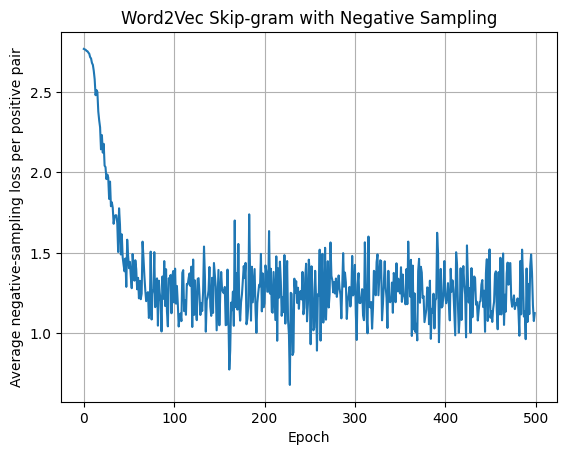


Words similar to cats: [('dogs', np.float64(0.978518274566058)), ('milk', np.float64(0.8879030852376589)), ('balls', np.float64(0.686015327961191))]
Words similar to dogs: [('cats', np.float64(0.978518274566058)), ('balls', np.float64(0.8165919907092746)), ('milk', np.float64(0.8025454791110299))]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Corpus
corpus = [
    "cats like milk",
    "cats drink milk",
    "dogs like milk",
    "dogs chase balls",
    "cats chase balls"
]

# 2. Build vocabulary
sentences = [s.split() for s in corpus]
vocab = sorted(set(word for s in sentences for word in s))

word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

V = len(vocab)
print("Vocabulary:", vocab)

# Hyperparameters
window = 1
d = 3
learning_rate = 0.05
epochs = 500
K = 3  # Number of negative samples per positive pair

# 3. Generate center-context pairs
pairs = []

for sentence in sentences:
    ids = [word_to_id[w] for w in sentence]

    for i, center in enumerate(ids):
        for j in range(max(0, i - window),
                       min(len(ids), i + window + 1)):
            if i != j:
                pairs.append((center, ids[j]))

print("Number of positive pairs:", len(pairs))

# 4. Initialize input and output embeddings
np.random.seed(42)

E = np.random.randn(V, d) * 0.1
W = np.random.randn(V, d) * 0.1

# 5. Create negative-sampling distribution
counts = np.zeros(V)

for sentence in sentences:
    for word in sentence:
        counts[word_to_id[word]] += 1

# Standard Word2Vec sampling distribution: frequency^0.75
neg_probs = counts ** 0.75
neg_probs = neg_probs / neg_probs.sum()

def sample_negatives(context, K):
    """Sample K words, excluding the positive context word."""
    negatives = []

    while len(negatives) < K:
        word = np.random.choice(V, p=neg_probs)

        if word != context:
            negatives.append(word)

    return negatives

# Numerically stable sigmoid
def sigmoid(x):
    x = np.clip(x, -15, 15)
    return 1.0 / (1.0 + np.exp(-x))

# 6. Train Skip-gram with negative sampling
losses = []

for epoch in range(epochs):
    np.random.shuffle(pairs)
    total_loss = 0.0

    for center, context in pairs:

        # Center-word embedding
        v = E[center].copy()

        # ---- Positive pair ----
        # The observed context word should have a high score.
        u = W[context].copy()
        score = np.dot(v, u)

        # -log(sigmoid(score))
        total_loss += np.logaddexp(0.0, -score)

        # Gradient of positive-pair loss w.r.t. score
        grad_score = sigmoid(score) - 1.0

        # Save gradients before updating either vector
        grad_center = grad_score * u
        grad_context = grad_score * v

        E[center] -= learning_rate * grad_center
        W[context] -= learning_rate * grad_context

        # ---- Negative pairs ----
        negatives = sample_negatives(context, K)

        for neg in negatives:
            v = E[center].copy()
            u_neg = W[neg].copy()

            score_neg = np.dot(v, u_neg)

            # -log(sigmoid(-score_neg))
            total_loss += np.logaddexp(0.0, score_neg)

            # Gradient of negative-pair loss w.r.t. score
            grad_score_neg = sigmoid(score_neg)

            grad_center = grad_score_neg * u_neg
            grad_negative = grad_score_neg * v

            E[center] -= learning_rate * grad_center
            W[neg] -= learning_rate * grad_negative

    losses.append(total_loss / len(pairs))

# 7. Print learned input embeddings
print("\nLearned word embeddings:")
for word, idx in word_to_id.items():
    print(word, np.round(E[idx], 3))

# 8. Plot average loss per positive pair
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Average negative-sampling loss per positive pair")
plt.title("Word2Vec Skip-gram with Negative Sampling")
plt.grid(True)
plt.show()

# 9. Compare word embeddings using cosine similarity
def cosine_similarity(a, b):
    return np.dot(a, b) / (
        np.linalg.norm(a) * np.linalg.norm(b) + 1e-12
    )

def similar_words(word, top_k=3):
    idx = word_to_id[word]
    results = []

    for j in range(V):
        if j != idx:
            sim = cosine_similarity(E[idx], E[j])
            results.append((id_to_word[j], sim))

    return sorted(results, key=lambda x: x[1], reverse=True)[:top_k]

print("\nWords similar to cats:", similar_words("cats"))
print("Words similar to dogs:", similar_words("dogs"))


In [ ]:
# ============================================================
# GloVe: Global Vectors for Word Representation
# From-scratch educational implementation using PyTorch
# ============================================================

import re
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter, defaultdict

# ------------------------------------------------------------
# 1. Set random seeds
# ------------------------------------------------------------

torch.manual_seed(42)
np.random.seed(42)

# ------------------------------------------------------------
# 2. Prepare the corpus
# ------------------------------------------------------------

corpus = [
    "ice is solid",
    "ice melts in water",
    "steam is a gas",
    "water turns into steam",
    "ice and water are related",
    "steam and gas are related",
    "cats drink milk",
    "dogs drink milk",
    "cats like milk",
    "dogs chase balls"
]

def tokenize(sentence):
    return re.findall(r"\b\w+\b", sentence.lower())

sentences = [tokenize(sentence) for sentence in corpus]

print("Tokenized corpus:")
for sentence in sentences:
    print(sentence)

# ------------------------------------------------------------
# 3. Build vocabulary
# ------------------------------------------------------------

word_counts = Counter(
    word
    for sentence in sentences
    for word in sentence
)

vocab = sorted(word_counts.keys())

word_to_id = {
    word: i for i, word in enumerate(vocab)
}

id_to_word = {
    i: word for word, i in word_to_id.items()
}

vocab_size = len(vocab)

print("\nVocabulary size:", vocab_size)
print("Vocabulary:", vocab)

# ------------------------------------------------------------
# 4. Build the co-occurrence matrix
# ------------------------------------------------------------

window_size = 2

cooccurrence = defaultdict(float)

for sentence in sentences:

    for i, target_word in enumerate(sentence):

        target_id = word_to_id[target_word]

        start = max(0, i - window_size)
        end = min(len(sentence), i + window_size + 1)

        for j in range(start, end):

            if i == j:
                continue

            context_word = sentence[j]
            context_id = word_to_id[context_word]

            distance = abs(i - j)

            # Closer context words receive greater weight
            cooccurrence[(target_id, context_id)] += (
                1.0 / distance
            )

# Display co-occurrence matrix
X = np.zeros((vocab_size, vocab_size), dtype=np.float32)

for (i, j), count in cooccurrence.items():
    X[i, j] = count

print("\nCo-occurrence matrix shape:", X.shape)
print("\nCo-occurrence matrix:")
print(X)

print("\nWord order:")
print(vocab)

# ------------------------------------------------------------
# 5. Extract observed word-context pairs
# ------------------------------------------------------------

pairs = list(cooccurrence.keys())

target_ids = torch.tensor(
    [i for i, j in pairs],
    dtype=torch.long
)

context_ids = torch.tensor(
    [j for i, j in pairs],
    dtype=torch.long
)

counts = torch.tensor(
    [cooccurrence[pair] for pair in pairs],
    dtype=torch.float32
)

# Log co-occurrence counts
log_counts = torch.log(counts)

print("\nNumber of observed pairs:", len(pairs))

# ------------------------------------------------------------
# 6. Define the GloVe model
# ------------------------------------------------------------

class GloVe(nn.Module):

    def __init__(self, vocab_size, embedding_dim):

        super().__init__()

        # Target word embeddings
        self.target_embeddings = nn.Embedding(
            vocab_size, embedding_dim
        )

        # Context word embeddings
        self.context_embeddings = nn.Embedding(
            vocab_size, embedding_dim
        )

        # Target biases
        self.target_bias = nn.Embedding(
            vocab_size, 1
        )

        # Context biases
        self.context_bias = nn.Embedding(
            vocab_size, 1
        )

        # Initialize embeddings
        nn.init.uniform_(
            self.target_embeddings.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        nn.init.uniform_(
            self.context_embeddings.weight,
            -0.5 / embedding_dim,
            0.5 / embedding_dim
        )

        nn.init.zeros_(self.target_bias.weight)
        nn.init.zeros_(self.context_bias.weight)

    def forward(self, target_ids, context_ids):

        target_vectors = self.target_embeddings(target_ids)

        context_vectors = self.context_embeddings(context_ids)

        # Dot product between target and context vectors
        dot_product = (
            target_vectors * context_vectors
        ).sum(dim=1)

        # Bias terms
        bias_target = self.target_bias(
            target_ids
        ).squeeze(1)

        bias_context = self.context_bias(
            context_ids
        ).squeeze(1)

        # Predicted log co-occurrence count
        prediction = (
            dot_product
            + bias_target
            + bias_context
        )

        return prediction


# ------------------------------------------------------------
# 7. Initialize model and optimizer
# ------------------------------------------------------------

embedding_dim = 20
epochs = 300
learning_rate = 0.03

x_max = 10.0
alpha = 0.75

model = GloVe(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim
)

optimizer = optim.Adagrad(
    model.parameters(),
    lr=learning_rate
)

# ------------------------------------------------------------
# 8. Define the GloVe weighting function
# ------------------------------------------------------------

weights = torch.where(
    counts < x_max,
    (counts / x_max) ** alpha,
    torch.ones_like(counts)
)

# ------------------------------------------------------------
# 9. Train the model
# ------------------------------------------------------------

for epoch in range(epochs):

    model.train()

    # Predict log co-occurrence counts
    predictions = model(
        target_ids,
        context_ids
    )

    # Weighted squared error
    loss = (
        weights * (predictions - log_counts) ** 2
    ).mean()

    # Backpropagation
    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    if (epoch + 1) % 50 == 0:

        print(
            f"Epoch {epoch + 1:3d}/{epochs}, "
            f"Loss = {loss.item():.6f}"
        )

# ------------------------------------------------------------
# 10. Extract final word embeddings
# ------------------------------------------------------------

model.eval()

with torch.no_grad():

    # Standard educational choice:
    # add target and context embeddings
    embeddings = (
        model.target_embeddings.weight
        + model.context_embeddings.weight
    ).cpu().numpy()

print("\nEmbedding matrix shape:", embeddings.shape)

# ------------------------------------------------------------
# 11. Get the embedding of a word
# ------------------------------------------------------------

def get_embedding(word):

    if word not in word_to_id:
        raise ValueError(
            f"Word '{word}' is not in the vocabulary."
        )

    return embeddings[word_to_id[word]]


print("\nEmbedding of 'ice':")
print(get_embedding("ice"))

print("\nEmbedding of 'steam':")
print(get_embedding("steam"))

# ------------------------------------------------------------
# 12. Calculate cosine similarity
# ------------------------------------------------------------

def cosine_similarity(word1, word2):

    v1 = get_embedding(word1)
    v2 = get_embedding(word2)

    denominator = (
        np.linalg.norm(v1)
        * np.linalg.norm(v2)
        + 1e-10
    )

    return float(np.dot(v1, v2) / denominator)


print("\nCosine similarities:")

print(
    "ice vs water:",
    round(cosine_similarity("ice", "water"), 4)
)

print(
    "ice vs steam:",
    round(cosine_similarity("ice", "steam"), 4)
)

print(
    "cats vs dogs:",
    round(cosine_similarity("cats", "dogs"), 4)
)

# ------------------------------------------------------------
# 13. Find most similar words
# ------------------------------------------------------------

def most_similar(word, top_k=5):

    vector = get_embedding(word)

    norms = np.linalg.norm(
        embeddings,
        axis=1
    )

    similarities = (
        embeddings @ vector
        / (
            norms * np.linalg.norm(vector)
            + 1e-10
        )
    )

    # Exclude the query word itself
    similarities[word_to_id[word]] = -np.inf

    # Get highest similarity scores
    indices = np.argsort(similarities)[::-1][:top_k]

    return [
        (
            id_to_word[i],
            round(float(similarities[i]), 4)
        )
        for i in indices
    ]


print("\nWords similar to 'ice':")
print(most_similar("ice"))

print("\nWords similar to 'steam':")
print(most_similar("steam"))

print("\nWords similar to 'cats':")
print(most_similar("cats"))

# ------------------------------------------------------------
# 14. Inspect a word-context prediction
# ------------------------------------------------------------

def predict_log_count(target_word, context_word):

    i = word_to_id[target_word]
    j = word_to_id[context_word]

    with torch.no_grad():

        prediction = model(
            torch.tensor([i]),
            torch.tensor([j])
        )

    return float(prediction.item())


target = "ice"
context = "water"

actual_count = X[
    word_to_id[target],
    word_to_id[context]
]

predicted_log_count = predict_log_count(
    target,
    context
)

print("\nPrediction inspection:")
print("Target word:", target)
print("Context word:", context)
print("Observed co-occurrence count:", actual_count)
print("Predicted log count:", round(predicted_log_count, 4))

print("\nGloVe training completed!")

Tokenized corpus:
['ice', 'is', 'solid']
['ice', 'melts', 'in', 'water']
['steam', 'is', 'a', 'gas']
['water', 'turns', 'into', 'steam']
['ice', 'and', 'water', 'are', 'related']
['steam', 'and', 'gas', 'are', 'related']
['cats', 'drink', 'milk']
['dogs', 'drink', 'milk']
['cats', 'like', 'milk']
['dogs', 'chase', 'balls']

Vocabulary size: 21
Vocabulary: ['a', 'and', 'are', 'balls', 'cats', 'chase', 'dogs', 'drink', 'gas', 'ice', 'in', 'into', 'is', 'like', 'melts', 'milk', 'related', 'solid', 'steam', 'turns', 'water']

Co-occurrence matrix shape: (21, 21)

Co-occurrence matrix:
[[0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  1.  0.  0.  0.  0.  0.
  0.5 0.  0. ]
 [0.  0.  1.  0.  0.  0.  0.  0.  1.  1.  0.  0.  0.  0.  0.  0.  0.  0.
  1.  0.  1. ]
 [0.  1.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  2.  0.
  0.  0.  1. ]
 [0.  0.  0.  0.  0.  1.  0.5 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  1.  0.